# Blinkit Sales Analysis — Python EDA

## 1. Project Introduction
This notebook analyzes the supplied item/outlet snapshot using descriptive statistics and visualizations. A row is an item/outlet record, not a transaction or quantity sold. The source does not specify sales currency or period. This repository is an adaptation of a project credited to Ashutosh Sahoo; see the repository LICENSE and README for attribution. Run cells from top to bottom.

## 2. Importing Libraries
Use pandas for tabular analysis, NumPy for numeric checks, and Matplotlib/Seaborn for charts.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")


## 3. Loading Dataset
Resolve the raw CSV relative to this notebook, regardless of the current working directory. Keep the supplied raw file unchanged; cleaning is performed on a copy.

In [2]:
ROOT = Path.cwd()
if not (ROOT / "Dataset").is_dir():
    ROOT = Path.cwd().parent if (Path.cwd().parent / "Dataset").is_dir() else ROOT
DATA_PATH = ROOT / "Dataset" / "BlinkIT Grocery Data.csv"
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Raw dataset not found: {DATA_PATH}")
raw_df = pd.read_csv(DATA_PATH)
df = raw_df.copy()
print(f"Loaded {len(df):,} records from {DATA_PATH}")

Loaded 8,523 records from c:\Users\Prafulyaar\Downloads\Blinkit_Data_Analysis-main\Blinkit_Data_Analysis-main\Dataset\BlinkIT Grocery Data.csv


In [3]:
df.head()

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Total Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2010,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2000,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


## 4. Dataset Overview
Review dimensions, field names, inferred types, and representative descriptive statistics before changing values.

In [4]:
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
df.info()
df.describe(include="all").T

Shape: (8523, 12)
Columns: ['Item Fat Content', 'Item Identifier', 'Item Type', 'Outlet Establishment Year', 'Outlet Identifier', 'Outlet Location Type', 'Outlet Size', 'Outlet Type', 'Item Visibility', 'Item Weight', 'Total Sales', 'Rating']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   object 
 1   Item Identifier            8523 non-null   object 
 2   Item Type                  8523 non-null   object 
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   object 
 5   Outlet Location Type       8523 non-null   object 
 6   Outlet Size                8523 non-null   object 
 7   Outlet Type                8523 non-null   object 
 8   Item Visibility            8523 non-null   float64
 9   Item Weight                70

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Item Fat Content,8523,5,Low Fat,5089,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item Identifier,8523,1559,FDW13,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item Type,8523,16,Fruits and Vegetables,1232,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outlet Establishment Year,8523.0,NaN,NaN,NaN,2010.831867,8.37176,1998.0,2000.0,2012.0,2017.0,2022.0
Outlet Identifier,8523,10,OUT027,935,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outlet Location Type,8523,3,Tier 3,3350,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outlet Size,8523,3,Medium,3631,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outlet Type,8523,4,Supermarket Type1,5577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item Visibility,8523.0,NaN,NaN,NaN,0.066132,0.051598,0.0,0.026989,0.053931,0.094585,0.328391
Item Weight,7060.0,NaN,NaN,NaN,12.857645,4.643456,4.555,8.77375,12.6,16.85,21.35


## 5. Data Cleaning
Normalize observed fat-content labels, standardize column names for analysis, and coerce measurable columns to numeric. Missing item weights are intentionally retained. No outlet age is derived because an age based on a fixed year becomes stale.

In [5]:
required_columns = {
    "Item Fat Content", "Item Identifier", "Item Type", "Outlet Establishment Year",
    "Outlet Identifier", "Outlet Location Type", "Outlet Size", "Outlet Type",
    "Item Visibility", "Item Weight", "Total Sales", "Rating",
}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")
df["Item Fat Content"] = (
    df["Item Fat Content"].astype("string").str.strip().str.lower()
    .replace({"lf": "low fat", "low fat": "low fat", "reg": "regular"})
    .map({"low fat": "Low Fat", "regular": "Regular"})
    .fillna(df["Item Fat Content"])
)
df = df.rename(columns={"Total Sales": "Sales"})
for column in ["Outlet Establishment Year", "Item Visibility", "Item Weight", "Sales", "Rating"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")
print("Fat content values:", sorted(df["Item Fat Content"].dropna().unique()))
df.dtypes

Fat content values: ['Low Fat', 'Regular']


Item Fat Content              object
Item Identifier               object
Item Type                     object
Outlet Establishment Year      int64
Outlet Identifier             object
Outlet Location Type          object
Outlet Size                   object
Outlet Type                   object
Item Visibility              float64
Item Weight                  float64
Sales                        float64
Rating                       float64
dtype: object

## 6. Missing Value Analysis
Missing values are reported by field and percentage. Item Weight is known to have missing observations; it is not required for the sales KPIs and is not imputed.

In [6]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
}).sort_values("missing_count", ascending=False)
missing_summary

,missing_count,missing_percent
Item Weight,1463,17.17
Item Fat Content,0,0.00
Item Type,0,0.00
Item Identifier,0,0.00
Outlet Establishment Year,0,0.00
Outlet Identifier,0,0.00
Outlet Size,0,0.00
Outlet Location Type,0,0.00
Outlet Type,0,0.00
Item Visibility,0,0.00


## 7. Duplicate Analysis
Check exact full-row duplicates; this is a row-identity check, not a claim that repeated product identifiers are duplicates.

In [7]:
duplicate_count = int(df.duplicated().sum())
print(f"Exact duplicate rows: {duplicate_count:,}")

Exact duplicate rows: 0


### Data Type Validation
Validate the required numeric measures before computing summary statistics.

In [8]:
print("Numeric type validation:")
for column in ["Outlet Establishment Year", "Item Visibility", "Item Weight", "Sales", "Rating"]:
    print(f"{column}: {df[column].dtype}")
assert pd.api.types.is_numeric_dtype(df["Sales"])
assert pd.api.types.is_numeric_dtype(df["Rating"])
assert df["Sales"].notna().all() and df["Rating"].notna().all()

Numeric type validation:
Outlet Establishment Year: int64
Item Visibility: float64
Item Weight: float64
Sales: float64
Rating: float64


### Outlier Detection
The IQR fences flag unusual sales values for review. Outliers are not automatically errors and are not removed.

In [9]:
# IQR flags are diagnostic only. Do not remove potential outliers without domain evidence.
q1, q3 = df["Sales"].quantile([0.25, 0.75])
iqr = q3 - q1
lower_fence, upper_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
sales_outliers = df.loc[~df["Sales"].between(lower_fence, upper_fence), "Sales"]
print(f"IQR lower fence: {lower_fence:.2f}; upper fence: {upper_fence:.2f}")
print(f"Potential sales outlier records: {len(sales_outliers):,} ({len(sales_outliers) / len(df):.2%})")

IQR lower fence: -43.90; upper fence: 323.37
Potential sales outlier records: 0 (0.00%)


In [10]:
## 8. Exploratory Data Analysis — Sales Contribution (comment)
sales_total = df["Sales"].sum()
contribution_by_fat = df.groupby("Item Fat Content")["Sales"].sum().to_frame("Total_Sales")
contribution_by_fat["Sales_Contribution_Pct"] = contribution_by_fat["Total_Sales"] / sales_total * 100
contribution_by_fat.sort_values("Total_Sales", ascending=False)

,Total_Sales,Sales_Contribution_Pct
Item Fat Content,,
Low Fat,776319.6784,64.602783
Regular,425361.8024,35.397217


## 8. Exploratory Data Analysis
Charts summarize recorded sales and ratings across categories. Group totals and group averages answer different questions; record counts are shown where helpful.

## 9. KPI Calculations
KPI definitions use the same complete dataset: sum and mean of Sales per record, count of non-missing Sales records, and mean Rating. No currency or quantity is inferred.

In [11]:
kpis = {
    "total_sales": df["Sales"].sum(),
    "average_sales_per_record": df["Sales"].mean(),
    "number_of_records": df["Sales"].count(),
    "average_rating": df["Rating"].mean(),
}
pd.Series(kpis, name="Value")

total_sales                 1.201681e+06
average_sales_per_record    1.409928e+02
number_of_records           8.523000e+03
average_rating              3.965857e+00
Name: Value, dtype: float64

### Sales by Fat Content
The chart compares each fat-content category's share of recorded sales. It describes the supplied records, not customer demand or units.

### Sales by Item Type
This chart ranks product categories by total recorded sales. Totals can reflect both average record value and the number of records.

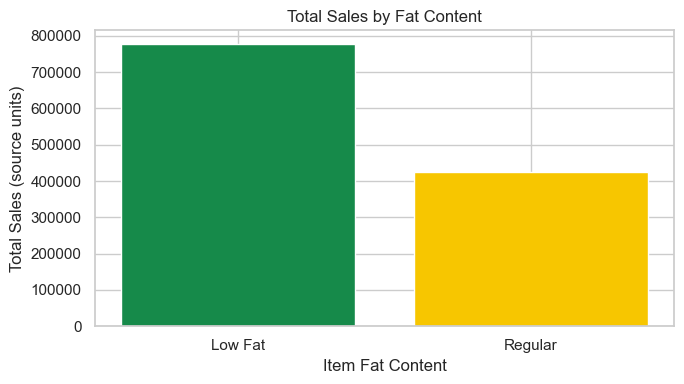

In [12]:
sales_by_fat = df.groupby("Item Fat Content")["Sales"].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(sales_by_fat.index, sales_by_fat.values, color=["#168A4A", "#F7C600"])
ax.set(title="Total Sales by Fat Content", xlabel="Item Fat Content", ylabel="Total Sales (source units)")
plt.tight_layout()
plt.show()

### Sales by Item Type
Horizontal bars make the full category ranking readable; the y-axis lists item categories and the x-axis is total recorded sales.

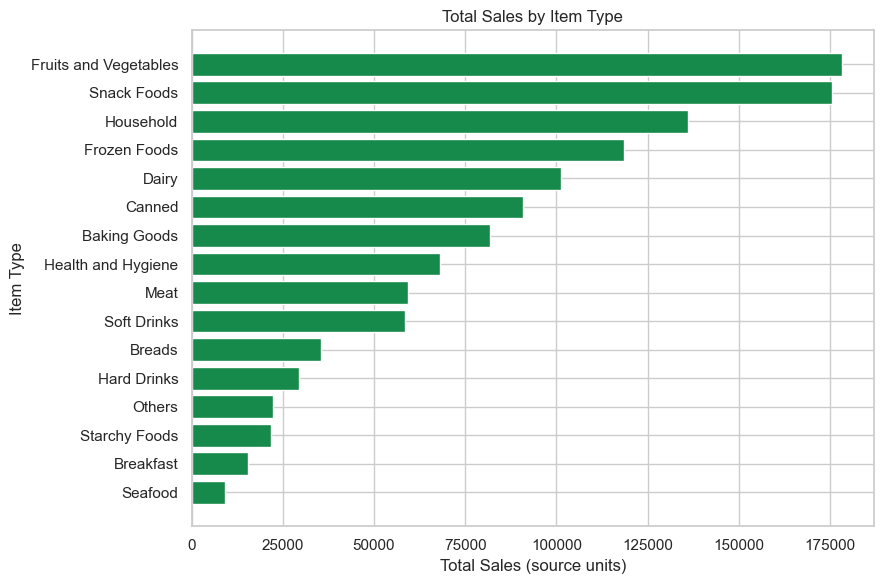

In [13]:
sales_by_type = df.groupby("Item Type")["Sales"].sum().sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(sales_by_type.index, sales_by_type.values, color="#168A4A")
ax.set(title="Total Sales by Item Type", xlabel="Total Sales (source units)", ylabel="Item Type")
plt.tight_layout()
plt.show()

### Sales by Outlet Size
This comparison shows total sales by supplied outlet-size group. The records in each group differ in count, so totals should not be read as per-record performance.

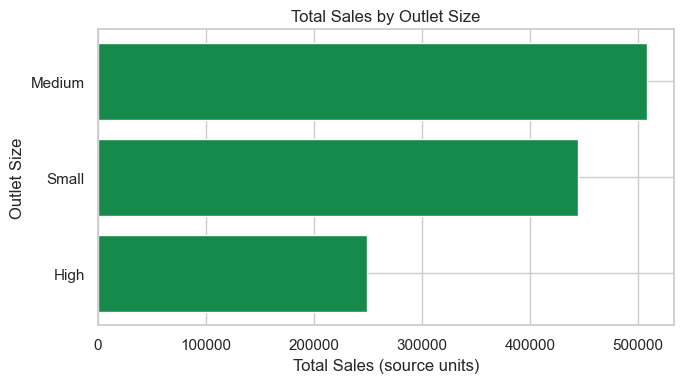

In [14]:
sales_by_size = df.groupby("Outlet Size")["Sales"].sum().sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(sales_by_size.index, sales_by_size.values, color="#168A4A")
ax.set(title="Total Sales by Outlet Size", xlabel="Total Sales (source units)", ylabel="Outlet Size")
plt.tight_layout()
plt.show()

### Sales by Location Tier
The bar chart compares total recorded sales across the three location tiers. Tier is a category here, not a time series.

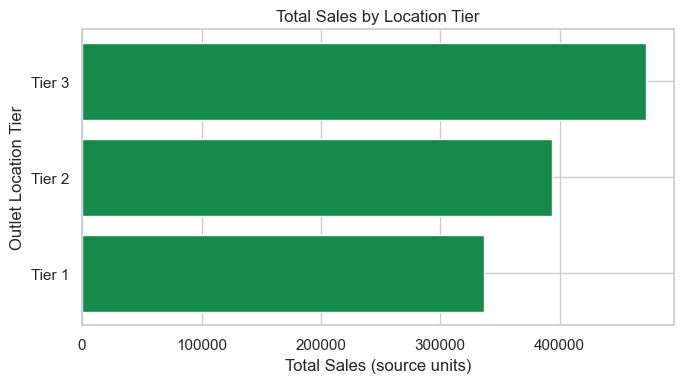

In [15]:
sales_by_location = df.groupby("Outlet Location Type")["Sales"].sum().sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(sales_by_location.index, sales_by_location.values, color="#168A4A")
ax.set(title="Total Sales by Location Tier", xlabel="Total Sales (source units)", ylabel="Outlet Location Tier")
plt.tight_layout()
plt.show()

### Average Rating by Item Type
This chart ranks mean ratings by category. Ratings are reported on the dataset's observed 1–5 scale; category record counts help contextualize averages.

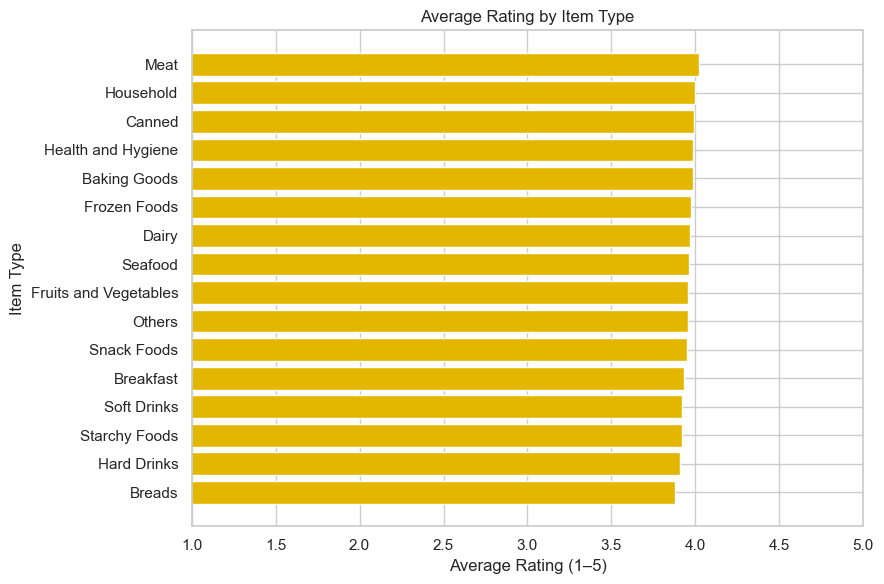

,Average_Rating,Records
Item Type,,
Breads,3.881275,251
Hard Drinks,3.907477,214
Starchy Foods,3.920270,148
Soft Drinks,3.920674,445
Breakfast,3.932727,110
Snack Foods,3.948917,1200
Others,3.954438,169
Fruits and Vegetables,3.956169,1232
Seafood,3.959375,64


In [16]:
rating_summary = df.groupby("Item Type").agg(Average_Rating=("Rating", "mean"), Records=("Rating", "count")).sort_values("Average_Rating")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(rating_summary.index, rating_summary["Average_Rating"], color="#E3B600")
ax.set(title="Average Rating by Item Type", xlabel="Average Rating (1–5)", ylabel="Item Type", xlim=(1, 5))
plt.tight_layout()
plt.show()
rating_summary

### Item Visibility versus Sales
Each point represents one record. The plot and Pearson correlation describe linear association in this snapshot; correlation does not prove causation.

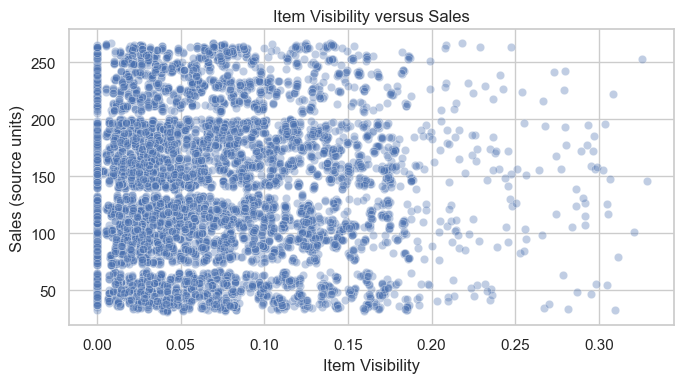

Pearson correlation (descriptive only): -0.0013


In [17]:
visibility_corr = df["Item Visibility"].corr(df["Sales"], method="pearson")
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=df, x="Item Visibility", y="Sales", alpha=0.35, ax=ax)
ax.set(title="Item Visibility versus Sales", xlabel="Item Visibility", ylabel="Sales (source units)")
plt.tight_layout()
plt.show()
print(f"Pearson correlation (descriptive only): {visibility_corr:.4f}")

,Total_Sales,Average_Sales_Per_Record,Number_Of_Records,Average_Rating
Outlet Type,,,,
Supermarket Type1,787549.8868,141.213894,5577,3.963242
Grocery Store,151939.1470,140.294688,1083,3.985873
Supermarket Type2,131477.7724,141.678634,928,3.971228
Supermarket Type3,130714.6746,139.801791,935,3.952941


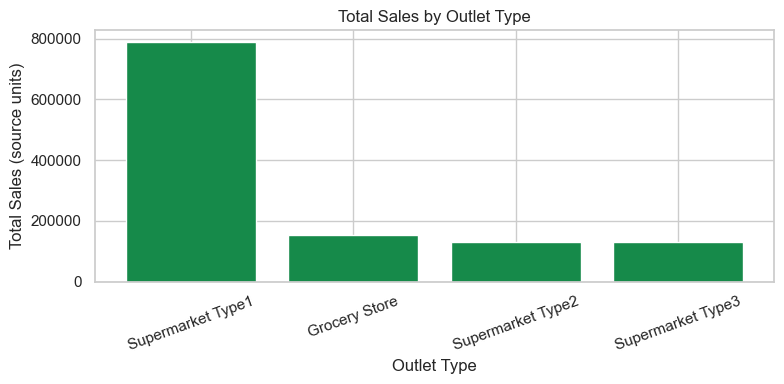

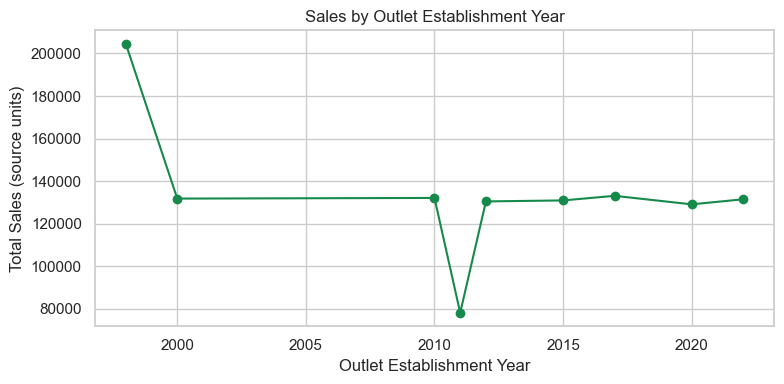

In [18]:
# Group table reports totals, average per record, counts, and ratings by outlet type.
outlet_type_summary = df.groupby("Outlet Type").agg(
    Total_Sales=("Sales", "sum"), Average_Sales_Per_Record=("Sales", "mean"),
    Number_Of_Records=("Sales", "count"), Average_Rating=("Rating", "mean")
).sort_values("Total_Sales", ascending=False)
display(outlet_type_summary)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(outlet_type_summary.index, outlet_type_summary["Total_Sales"], color="#168A4A")
ax.set(title="Total Sales by Outlet Type", xlabel="Outlet Type", ylabel="Total Sales (source units)")
ax.tick_params(axis="x", labelrotation=20)
plt.tight_layout()
plt.show()

sales_by_year = df.groupby("Outlet Establishment Year")["Sales"].sum().sort_index()
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sales_by_year.index, sales_by_year.values, marker="o", color="#168A4A")
ax.set(title="Sales by Outlet Establishment Year", xlabel="Outlet Establishment Year", ylabel="Total Sales (source units)")
plt.tight_layout()
plt.show()

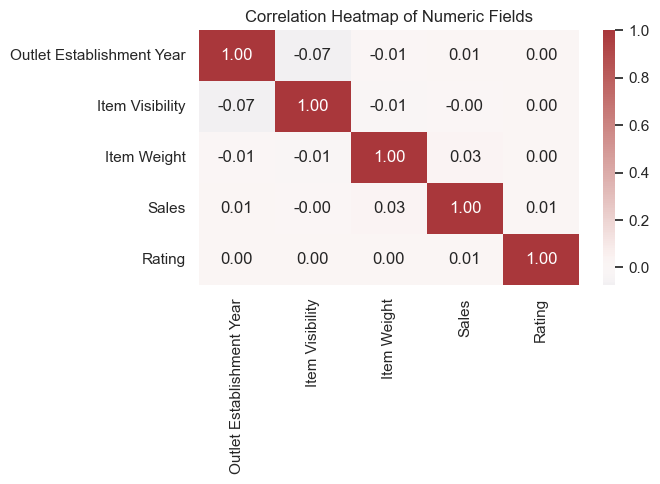

In [19]:
# Correlation heatmap for numeric measures; this is descriptive and not causal.
numeric_columns = ["Outlet Establishment Year", "Item Visibility", "Item Weight", "Sales", "Rating"]
correlation_matrix = df[numeric_columns].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Correlation Heatmap of Numeric Fields")
plt.tight_layout()
plt.show()

## 10. Business Insights
The summary below calculates findings directly from the loaded data. It reports descriptive rankings and relative comparisons only.

In [20]:
top_item_type = df.groupby("Item Type")["Sales"].sum().idxmax()
top_location_tier = df.groupby("Outlet Location Type")["Sales"].sum().idxmax()
top_outlet = df.groupby("Outlet Identifier")["Sales"].sum().idxmax()
category_summary = df.groupby("Item Type").agg(total_sales=("Sales", "sum"), average_rating=("Rating", "mean"))
high_rating_low_sales = category_summary[
    (category_summary["average_rating"] > df["Rating"].mean())
    & (category_summary["total_sales"] < category_summary["total_sales"].mean())
].sort_values("total_sales")
print(f"Highest sales item type: {top_item_type}")
print(f"Highest sales location tier: {top_location_tier}")
print(f"Highest sales outlet identifier: {top_outlet}")
print("Categories above the dataset-wide mean rating and below mean category sales:")
display(high_rating_low_sales)

Highest sales item type: Fruits and Vegetables
Highest sales location tier: Tier 3
Highest sales outlet identifier: OUT035
Categories above the dataset-wide mean rating and below mean category sales:


,total_sales,average_rating
Item Type,,
Meat,59449.8638,4.023059
Health and Hygiene,68025.8388,3.986154


## 11. Recommendations
Use the descriptive results to prioritize questions for follow-up, not to assert causes. For example, compare category-level sales with ratings and record counts before proposing merchandising experiments. Validate any action with transaction-level, time-period, and operational data that this snapshot does not contain.

## 12. Conclusion
The notebook provides a reproducible descriptive review of the included data. Conclusions are limited by missing item weights, absent transaction dates and quantities, and undocumented sales currency/period.